# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

This studio uses our cleaned September 2024 transactions and follows the cleaning functions in the team notebook. I compare reported positive SKU units, calculate a baseline for each product family, and check how the results differ by store.

The product grouping below is a working analysis mapping based on the catalog names. It extends the team's Pop-Tarts mapping for this studio and still needs Mouad's review before final integration. Package sizes conflict in the catalog, so reported units are not individual items, liters, or equivalent packs.

### Setup and cleaning

These two cells copy the team notebook's cleaning pipeline and validation checks so this notebook runs on its own from inside the cloned repository. No weather API call is needed for this studio.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# Find the team repository
REPO_NAME = "F26-DS2002-Midterm-Repo-Nate-Mohamed-Mouad"

def find_repo_root():
    here = Path.cwd()

    folders = [
        here,
        *here.parents,
        Path("/content") / REPO_NAME
    ]

    for folder in folders:
        if (
                (folder / "CHARTER.md").is_file()
                and (folder / "data" / "walmart_transactions.csv").is_file()
        ):
            return folder

    raise FileNotFoundError(
        "Team repository not found. Open this notebook "
        "from your cloned repo or clone the repo into Colab."
    )


REPO_ROOT = find_repo_root()

def find_data(filename):
    path = REPO_ROOT / "data" / filename

    if not path.is_file():
        raise FileNotFoundError(filename)

    return path


# Load the transaction and store files
raw = pd.read_csv(
    find_data("walmart_transactions.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

stores_raw = pd.read_csv(
    find_data("store_locations.csv"),
    na_values=["NULL", "N/A", "NaN"]
)

print("Original transactions:", len(raw))
print("Store reference rows:", len(stores_raw))


# Standardize store IDs
def clean_store_id(series):
    return (
        series.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(
            r"^FL[-_\s]*(\d+)$",
            r"FL-\1",
            regex=True
        )
    )


# Parse different timestamp formats
def clean_dates(series):
    formats = [
        "%Y-%m-%dT%H:%M:%S",
        "%Y-%m-%d %H:%M:%S",
        "%Y-%m-%d %H:%M",
        "%m/%d/%Y %H:%M",
        "%m/%d/%Y %H:%M:%S",
        "%m-%d-%Y %H:%M:%S",
        "%m-%d-%Y %H:%M",
        "%d-%b-%Y %H:%M",
        "%d-%b-%Y %H:%M:%S"
    ]

    result = pd.Series(
        pd.NaT,
        index=series.index,
        dtype="datetime64[ns]"
    )

    for fmt in formats:
        parsed = pd.to_datetime(
            series,
            format=fmt,
            errors="coerce"
        )

        result = result.fillna(parsed)

    return result


# Standardize category labels
CATEGORY_ALIASES = {
    "Alcoholic Beverages": "Alcohol",
    "Baby Products": "Baby",
    "Breakfast Foods": "Breakfast",
    "Emergency Supplies": "Emergency",
    "Games & Entertainment": "Entertainment",
    "Groceries": "Grocery",
    "Health & Wellness": "Health",
    "Household Essentials": "Household"
}


def clean_category(series):
    return (
        series.astype("string")
        .str.strip()
        .str.title()
        .replace(CATEGORY_ALIASES)
    )


# Main transaction cleaning function
def clean_transactions(df):
    cleaned = df.copy()
    log = []

    # 1. Remove exact duplicate rows
    before = len(cleaned)
    cleaned = cleaned.drop_duplicates().copy()

    log.append({
        "dataset": "transactions",
        "step": "Remove exact duplicates",
        "before": before,
        "after": len(cleaned),
        "affected": before - len(cleaned)
    })

    # Helper for logging steps that do not remove rows
    def log_step(step, affected):
        log.append({
            "dataset": "transactions",
            "step": step,
            "before": len(cleaned),
            "after": len(cleaned),
            "affected": int(affected)
        })

    # 2. Standardize store IDs
    cleaned["store_id_clean"] = clean_store_id(
        cleaned["store_id"]
    )

    changed_stores = (
            cleaned["store_id"].astype("string")
            != cleaned["store_id_clean"]
    ).fillna(False).sum()

    log_step("Standardize store IDs", changed_stores)

    # 3. Parse timestamps
    cleaned["timestamp_clean"] = clean_dates(
        cleaned["timestamp"]
    )

    # Create daily dates for the weather join
    cleaned["date"] = (
        cleaned["timestamp_clean"].dt.normalize()
    )

    log_step(
        "Parse nonmissing timestamps",
        cleaned["timestamp_clean"].notna().sum()
    )

    log_step(
        "Flag missing / unparseable timestamps",
        cleaned["timestamp_clean"].isna().sum()
    )

    log_step(
        "Create daily date keys",
        cleaned["date"].notna().sum()
    )

    # 4. Convert prices into numeric values
    price_text = cleaned["unit_price"].astype("string")

    formatted_prices = price_text.str.contains(
        r"\$|^\s|\s$",
        regex=True,
        na=False
    ).sum()

    cleaned["unit_price_clean"] = pd.to_numeric(
        price_text
        .str.strip()
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    log_step(
        "Clean formatted unit prices",
        formatted_prices
    )

    log_step(
        "Flag missing/unparseable unit prices",
        cleaned["unit_price_clean"].isna().sum()
    )

    # 5. Convert quantities and flag possible returns
    cleaned["quantity_clean"] = pd.to_numeric(
        cleaned["quantity"],
        errors="coerce"
    )

    cleaned["possible_return"] = (
            cleaned["quantity_clean"] < 0
    )

    log_step(
        "Flag negative quantities",
        cleaned["possible_return"].sum()
    )

    log_step(
        "Flag missing/unparseable quantities",
        cleaned["quantity_clean"].isna().sum()
    )

    # 6. Standardize SKUs
    cleaned["sku_clean"] = (
        cleaned["sku"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    changed_skus = (
            cleaned["sku"].astype("string")
            != cleaned["sku_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize SKU formatting",
        changed_skus
    )

    # 7. Standardize categories
    cleaned["category_clean"] = clean_category(
        cleaned["category"]
    )

    changed_categories = (
            cleaned["category"].astype("string")
            != cleaned["category_clean"]
    ).fillna(False).sum()

    log_step(
        "Standardize category formatting and aliases",
        changed_categories
    )

    return cleaned, pd.DataFrame(log)

Original transactions: 25562
Store reference rows: 14


In [2]:
# Run the cleaning function
clean, decision_log = clean_transactions(raw)


# Standardize the store reference data
stores_clean = stores_raw.copy()

stores_clean["store_id_clean"] = clean_store_id(
    stores_clean["store_id"]
)

# Check that store aliases do not have conflicting details
conflicts = stores_clean.groupby("store_id_clean")[
    ["city", "state", "latitude", "longitude"]
].nunique(dropna=True)

assert not conflicts.gt(1).any().any(), (
    "Conflicting store information was found."
)

# Remove duplicate store aliases
stores_clean = stores_clean.drop_duplicates(
    subset="store_id_clean"
).copy()

# Add the store-reference decision to the log
store_log = pd.DataFrame([{
    "dataset": "store_locations",
    "step": "Consolidate duplicate store ID aliases",
    "before": len(stores_raw),
    "after": len(stores_clean),
    "affected": len(stores_raw) - len(stores_clean)
}])

decision_log = pd.concat(
    [decision_log, store_log],
    ignore_index=True
)


# Show cleaning results
print("Original transactions:", len(raw))
print("Cleaned transactions:", len(clean))
print("Rows removed:", len(raw) - len(clean))

print("Unique cleaned stores:",
      clean["store_id_clean"].nunique())

print("Original category labels:",
      raw["category"].nunique())

print("Cleaned category labels:",
      clean["category_clean"].nunique())

print("\nCleaning decision log:")
display(decision_log)


# Verify that the correct number of duplicates was removed
assert len(clean) == (
        len(raw) - raw.duplicated().sum()
)

assert not clean.duplicated(
    subset=raw.columns.tolist()
).any()

# Check numeric columns
assert clean["unit_price_clean"].notna().all(), (
    "Some prices are missing or could not be converted."
)

assert clean["quantity_clean"].notna().all(), (
    "Some quantities are missing or could not be converted."
)

# Confirm stores match the reference file
assert clean["store_id_clean"].isin(
    stores_clean["store_id_clean"]
).all(), "Some store IDs did not match."

# Check timestamp parsing
assert (
        clean["timestamp_clean"].isna().sum()
        == clean["timestamp"].isna().sum()
), "Some nonmissing timestamps failed to parse."

# Check date format for weather analysis
assert pd.api.types.is_datetime64_any_dtype(
    clean["date"]
)

assert clean.loc[
    clean["date"].notna(), "date"
].dt.hour.eq(0).all()

print("\nAll initial cleaning checks passed!")


# Check the transaction timeline
daily_orders = (
    clean.dropna(subset=["date"])
    .groupby("date")
    .size()
)

print("\nFirst sales date:",
      daily_orders.index.min().date())

print("Last sales date:",
      daily_orders.index.max().date())

print("Peak daily order date:",
      daily_orders.idxmax().date())

print("Peak daily transaction records:",
      int(daily_orders.max()))

Original transactions: 25562
Cleaned transactions: 25532
Rows removed: 30
Unique cleaned stores: 12
Original category labels: 37
Cleaned category labels: 10

Cleaning decision log:


,dataset,step,before,after,affected
0,transactions,Remove exact duplicates,25562,25532,30
1,transactions,Standardize store IDs,25532,25532,4345
2,transactions,Parse nonmissing timestamps,25532,25532,24648
3,transactions,Flag missing / unparseable timestamps,25532,25532,884
4,transactions,Create daily date keys,25532,25532,24648
5,transactions,Clean formatted unit prices,25532,25532,4329
6,transactions,Flag missing/unparseable unit prices,25532,25532,0
7,transactions,Flag negative quantities,25532,25532,130
8,transactions,Flag missing/unparseable quantities,25532,25532,0
9,transactions,Standardize SKU formatting,25532,25532,0



All initial cleaning checks passed!

First sales date: 2024-09-01
Last sales date: 2024-09-30
Peak daily order date: 2024-09-14
Peak daily transaction records: 2007


### Analysis decisions

| Issue | Decision | Reason |
|---|---|---|
| Baseline | September 1–4, 2024, inclusive; mean per calendar day | Uses the same early-month window as our team weather analysis, before the visible rise. Four days is short, so a September 1–7 sensitivity check is also shown. |
| Surge | Highest daily quantity before September 26 divided by the baseline daily mean | Gives a consistent descriptive peak multiple for each family. It does not establish that the hurricane caused the increase. |
| Landfall | September 26, 2024 | Uses the date already stated in the team's Q3 analysis. |
| Quantities | Positive reported SKU units; exclude zero/negative quantities from demand analysis | Follows the existing Pop-Tarts comparison. Returns remain in the cleaned data. |
| Missing dates | Exclude from daily analysis and print the excluded count | We cannot assign undated purchases to a day. |
| Product aliases | Explicit catalog-based family mapping, preserving each SKU and package size | Prevents fragmented product names from splitting the comparison. |
| Package conflicts | Do not multiply by inconsistent package counts | Totals describe reported SKU units, not equal physical amounts of product. |
| Missing daily groups | Fill absent product/store combinations with zero within the observed month | Assumes the transaction extract covers each calendar day; missing reporting cannot be distinguished from no sales. |
| Geography | Compare store cities and regions | No storm track is supplied; this table cannot establish a distance gradient. |

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

products = pd.read_csv(find_data("product_catalog.csv"))
products["sku_clean"] = products["sku"].astype("string").str.strip().str.upper()

# Keep the grouping explicit so the team can review each decision
product_groups = {
    "Strawberry Pop-Tarts": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "Bottled water": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "AA batteries": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "LED flashlights": ["FLASH-01", "LED-FLASH"],
    "Light beer": ["BEER-24", "LTBEER24"],
    "Monopoly": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "Playing cards": ["CARDS-01", "PLAYCARD-STD"],
    "Streaming devices": ["STREAM-01", "ROKU-STD"],
    "Canned soup": ["SOUP-CAN", "CNSOUP-01"],
    "White bread": ["BREAD-WH", "WHITEBREAD"],
    "Peanut butter": ["PB-16", "PNUTBTR-16"],
    "Emergency candles": ["CNDL-EM", "CANDLE-EMRG"],
    "First-aid kits": ["FAID-01", "FIRSTAID-KIT"],
    "Portable chargers": ["CHRG-PORT", "PORTCHARGER"],
    "Chips variety packs": ["CHIPS-VP", "CHIPVARIETY"],
    "Paper towels": ["PTOWEL-6", "PAPERTOWEL6"],
    "Toilet paper": ["TP-12", "TOILETPAPER12"],
    "Size 3 diapers": ["DIAP-S3", "DIAPERS-3"],
    "Infant formula": ["BFORM-01", "BABYFORMULA"],
    "Heavy-duty tarps": ["TARP-HD", "HDTARP-01"]
}

mapping = pd.DataFrame([
    {"sku_clean": sku, "product_family": family}
    for family, skus in product_groups.items()
    for sku in skus
])
assert mapping["sku_clean"].is_unique
assert set(mapping["sku_clean"]) == set(products["sku_clean"])

mapping = mapping.merge(
    products[["sku_clean", "product_name", "package_size"]],
    on="sku_clean", how="left", validate="one_to_one"
)
sales = clean.merge(mapping, on="sku_clean", how="left", validate="many_to_one",
                    suffixes=("", "_catalog"))
assert len(sales) == len(clean)
assert sales["product_family"].notna().all()

analysis_sales = sales.loc[
    sales["date"].notna() & sales["quantity_clean"].gt(0)
].copy()
print("Undated rows excluded:", int(sales["date"].isna().sum()))
print("Nonpositive quantity rows excluded (may overlap undated):",
      int(sales["quantity_clean"].le(0).sum()))
print("Rows used:", len(analysis_sales))
print("Catalog SKUs:", len(mapping))
print("Working product families:", mapping["product_family"].nunique())
display(mapping)

LANDFALL = pd.Timestamp("2024-09-26")
BASELINE_START = pd.Timestamp("2024-09-01")
BASELINE_END = pd.Timestamp("2024-09-04")
calendar = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")
assert len(calendar) == sales["date"].nunique()

daily = analysis_sales.pivot_table(
    index="date", columns="product_family", values="quantity_clean",
    aggfunc="sum", fill_value=0
).reindex(calendar, fill_value=0)
daily.index.name = "date"
assert daily.to_numpy().sum() == analysis_sales["quantity_clean"].sum()

baseline = daily.loc[BASELINE_START:BASELINE_END].mean()
assert baseline.gt(0).all()
pre_landfall = daily.loc[daily.index < LANDFALL]
surge = pd.DataFrame({
    "baseline_units_per_day": baseline,
    "peak_reported_units": pre_landfall.max(),
    "peak_date": pre_landfall.idxmax(),
    "surge_multiple": pre_landfall.max() / baseline
}).sort_values("surge_multiple", ascending=False)
surge["days_before_landfall"] = (LANDFALL - surge["peak_date"]).dt.days
print("Baseline: September 1–4, 2024, inclusive (4 calendar days)")
display(surge.round(2))

# Use the same five families on both charts for a fair comparison
chart_products = surge.head(5).index.tolist()
chart_names = []
colors = ["#24323E", "#F67132", "#21688D", "#6B8E23", "#9467BD"]

def finish_chart(ax, title, ylabel):
    ax.axvline(LANDFALL, color="gray", linestyle="--", label="Landfall (Sept 26)")
    ax.axvspan(BASELINE_START, BASELINE_END + pd.Timedelta(days=1),
               color="gray", alpha=0.1, label="Baseline: Sept 1–4")
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Date (September 2024)")
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()

Undated rows excluded: 884
Nonpositive quantity rows excluded (may overlap undated): 130
Rows used: 24521
Catalog SKUs: 45
Working product families: 20


,sku_clean,product_family,product_name,package_size
0,PT-12,Strawberry Pop-Tarts,pop-tarts strawberry,4-pack
1,SKU#459812,Strawberry Pop-Tarts,Strawberry Pop-Tart,4pk
2,POPTART-STRAW,Strawberry Pop-Tarts,Pop-Tarts Strawberry,6 pack
3,PT_STRAWBERRY,Strawberry Pop-Tarts,pop-tarts strawberry,4 pack
4,WTR-24,Bottled water,BOTTLED WATER 24PK,1 pack
5,WATER24PK,Bottled water,Bottled Water 24-Pack,24 pack
6,WTR_24PK,Bottled water,Water - 24 Pack,1 pack
7,BATT-100,AA batteries,BATTERIES AA 4PK,6 pack
8,BAT-AA4,AA batteries,AA Batteries 4-Pack,4pk
9,BATT_AA_4PK,AA batteries,AA Batteries 4-Pack,24 pack


Baseline: September 1–4, 2024, inclusive (4 calendar days)


,baseline_units_per_day,peak_reported_units,peak_date,surge_multiple,days_before_landfall
product_family,,,,,
Strawberry Pop-Tarts,71.50,678,2024-09-14,9.48,12
LED flashlights,56.00,290,2024-09-14,5.18,12
Bottled water,102.75,504,2024-09-13,4.91,13
Monopoly,37.75,178,2024-09-14,4.72,12
Portable chargers,40.50,180,2024-09-13,4.44,13
Emergency candles,56.50,249,2024-09-13,4.41,13
Heavy-duty tarps,46.00,200,2024-09-14,4.35,12
AA batteries,90.75,365,2024-09-14,4.02,12
First-aid kits,39.75,150,2024-09-13,3.77,13


### Pattern 1 — products moving together before landfall

I plot the five product families with the largest relative surges. The quantities below are reported sales units, so package-size differences still limit physical-volume comparisons.

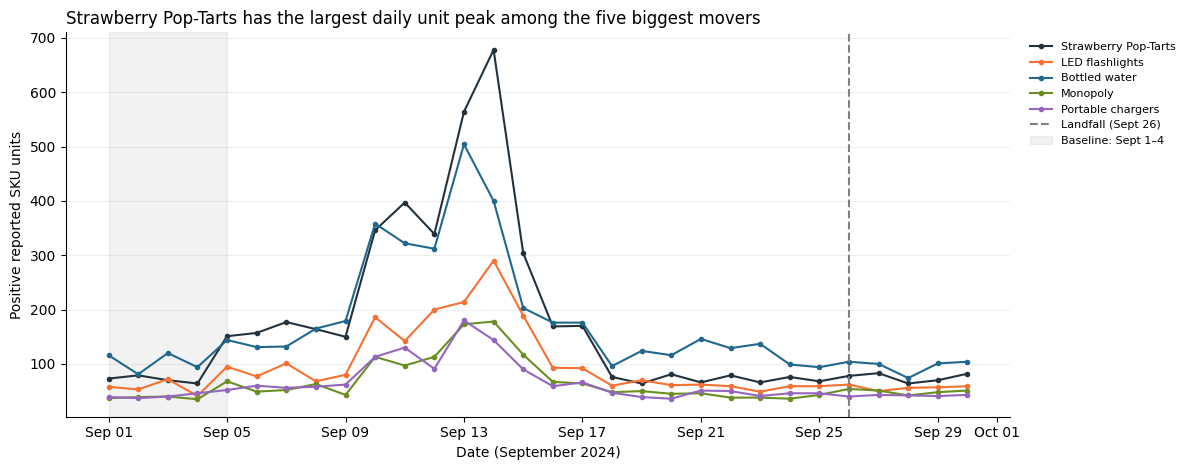

In [4]:
raw_leader = daily[chart_products].max().idxmax()
fig, ax = plt.subplots(figsize=(12, 4.8))
for family, color in zip(chart_products, colors):
    ax.plot(daily.index, daily[family], marker="o", ms=3, color=color, label=family)
finish_chart(ax, f"{raw_leader} has the largest daily unit peak among the five biggest movers",
             "Positive reported SKU units")
plt.show()
chart_names.append("Raw daily product sales")

### Pattern 2 — indexing to baseline

Each family is divided by its own September 1–4 daily mean. A value of 1.0 means baseline, and 5.0 means five times baseline. The ranking uses the highest daily value before landfall, not a multi-day surge average.

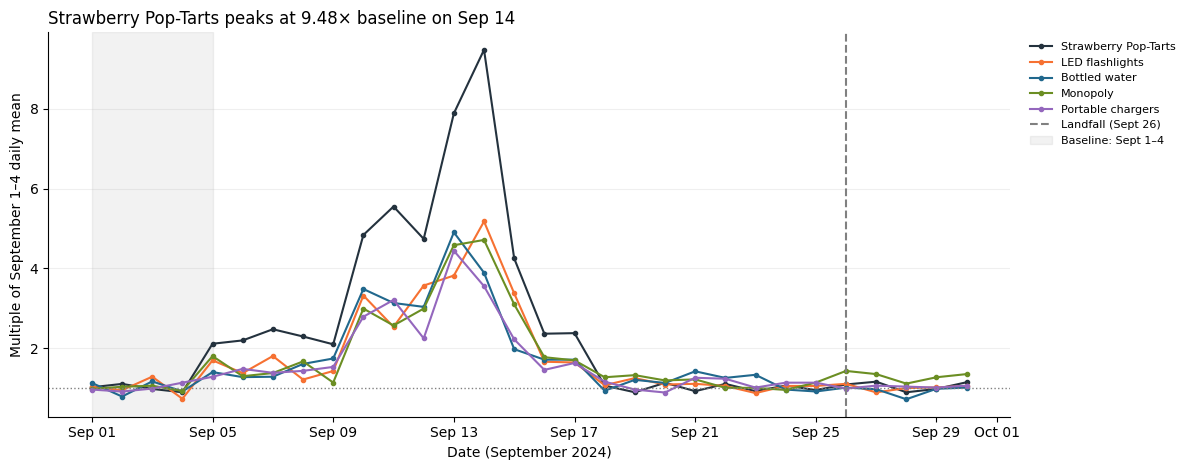

Top relative mover: Strawberry Pop-Tarts, 9.48x baseline.
Peak occurred 12 days before the team's landfall date.
This is an early-month surge, not evidence that landfall caused demand.


,Sept_1_4_multiple,Sept_1_7_multiple
product_family,,
Strawberry Pop-Tarts,9.48,6.16
LED flashlights,5.18,4.08
Bottled water,4.91,4.31
Monopoly,4.72,3.89
Portable chargers,4.44,3.82
Emergency candles,4.41,3.64
Heavy-duty tarps,4.35,3.68
AA batteries,4.02,3.22
First-aid kits,3.77,3.12


Top mover using September 1–7: Strawberry Pop-Tarts
The wider window includes part of the rise and is a sensitivity check, not a replacement baseline.


In [5]:
indexed = daily.div(baseline)
top_product = surge.index[0]
surge_multiple = float(surge.loc[top_product, "surge_multiple"])
peak_date = surge.loc[top_product, "peak_date"]

fig, ax = plt.subplots(figsize=(12, 4.8))
for family, color in zip(chart_products, colors):
    ax.plot(indexed.index, indexed[family], marker="o", ms=3, color=color, label=family)
ax.axhline(1, color="gray", linestyle=":", linewidth=1)
finish_chart(ax, f"{top_product} peaks at {surge_multiple:.2f}× baseline on {peak_date:%b %d}",
             "Multiple of September 1–4 daily mean")
plt.show()
chart_names.append("Indexed daily product sales")

print(f"Top relative mover: {top_product}, {surge_multiple:.2f}x baseline.")
print(f"Peak occurred {(LANDFALL - peak_date).days} days before the team's landfall date.")
print("This is an early-month surge, not evidence that landfall caused demand.")

# Check how strongly the result depends on the short baseline
alternate_baseline = daily.loc["2024-09-01":"2024-09-07"].mean()
sensitivity = pd.DataFrame({
    "Sept_1_4_multiple": surge["surge_multiple"],
    "Sept_1_7_multiple": pre_landfall.max() / alternate_baseline
}).sort_values("Sept_1_4_multiple", ascending=False)
display(sensitivity.round(2))
print("Top mover using September 1–7:", sensitivity["Sept_1_7_multiple"].idxmax())
print("The wider window includes part of the rise and is a sensitivity check, not a replacement baseline.")

### Pattern 3 — before-and-after for Q2

Strawberry Pop-Tarts is the largest alias group, with four SKUs. I compare all dated positive sales in September, before and after grouping. The multiple below compares the consolidated total with the largest individual SKU total; it is a consolidation multiple, not a surge multiple. The package-size differences remain visible in the supporting table.

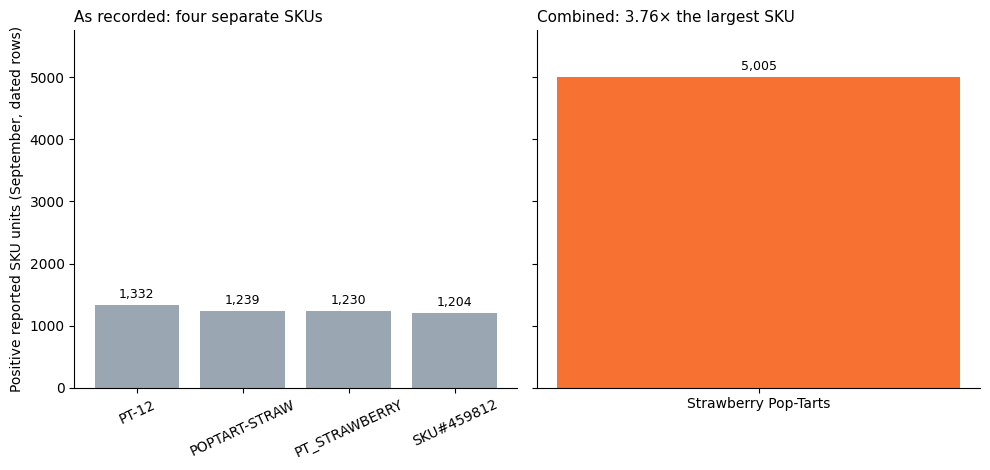

,sku_clean,product_family,product_name,package_size
0,PT-12,Strawberry Pop-Tarts,pop-tarts strawberry,4-pack
1,SKU#459812,Strawberry Pop-Tarts,Strawberry Pop-Tart,4pk
2,POPTART-STRAW,Strawberry Pop-Tarts,Pop-Tarts Strawberry,6 pack
3,PT_STRAWBERRY,Strawberry Pop-Tarts,pop-tarts strawberry,4 pack


Combined dated reported quantity: 5005
Largest individual SKU quantity: 1332
Consolidation multiple: 3.76
Grouping preserves the total; it changes how much demand is visible under one name.


In [6]:
pop_sales = analysis_sales.loc[
    analysis_sales["product_family"].eq("Strawberry Pop-Tarts")
]
sku_totals = pop_sales.groupby("sku_clean")["quantity_clean"].sum().sort_values(ascending=False)
combined = sku_totals.sum()
consolidation_multiple = combined / sku_totals.max()
assert combined == pop_sales["quantity_clean"].sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True)
axes[0].bar(sku_totals.index, sku_totals.values, color="#9AA7B2")
axes[0].set_title("As recorded: four separate SKUs", loc="left", fontsize=11)
axes[0].tick_params(axis="x", labelrotation=25)
axes[1].bar(["Strawberry Pop-Tarts"], [combined], color="#F67132")
axes[1].set_title(f"Combined: {consolidation_multiple:.2f}× the largest SKU", loc="left", fontsize=11)
axes[0].set_ylabel("Positive reported SKU units (September, dated rows)")
for ax in axes:
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for bar in ax.patches:
        ax.annotate(f"{bar.get_height():,.0f}",
                    (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 5), textcoords="offset points", ha="center", fontsize=9)
axes[0].set_ylim(0, combined * 1.15)
plt.tight_layout()
plt.show()
chart_names.append("Pop-Tarts before and after consolidation")

display(mapping.loc[mapping["product_family"].eq("Strawberry Pop-Tarts")])
print("Combined dated reported quantity:", int(combined))
print("Largest individual SKU quantity:", int(sku_totals.max()))
print("Consolidation multiple:", round(consolidation_multiple, 2))
print("Grouping preserves the total; it changes how much demand is visible under one name.")

### Pattern 4 — Q4, stores and geography

I use a table for the 12 stores, with each store's own baseline and peak. These are all-product reported quantities, so product mix and package sizes can affect comparisons. Peaks can occur on different dates. Region is the supplied geographic grouping; it is not distance from the storm path. Missing coordinates, including Tallahassee's, are retained and flagged.

In [7]:
daily_store = analysis_sales.pivot_table(
    index="date", columns="store_id_clean", values="quantity_clean",
    aggfunc="sum", fill_value=0
).reindex(calendar, fill_value=0)
store_baseline = daily_store.loc[BASELINE_START:BASELINE_END].mean()
assert store_baseline.gt(0).all()
store_pre = daily_store.loc[daily_store.index < LANDFALL]
by_store = pd.DataFrame({
    "baseline_units_per_day": store_baseline,
    "peak_units": store_pre.max(),
    "peak_date": store_pre.idxmax(),
    "surge_multiple": store_pre.max() / store_baseline,
    "transaction_rows": analysis_sales.groupby("store_id_clean").size()
}).rename_axis("store_id_clean").reset_index()
by_store = by_store.merge(
    stores_clean[["store_id_clean", "city", "region", "latitude", "longitude"]],
    on="store_id_clean", how="left", validate="one_to_one"
)
by_store["region"] = by_store["region"].str.strip()
by_store["coordinates_available"] = by_store[["latitude", "longitude"]].notna().all(axis=1)
assert len(by_store) == stores_clean["store_id_clean"].nunique()
assert by_store["city"].notna().all()
assert by_store["transaction_rows"].sum() == len(analysis_sales)
by_store = by_store.sort_values("surge_multiple", ascending=False)
display(by_store[["store_id_clean", "city", "region", "baseline_units_per_day",
                  "peak_units", "peak_date", "surge_multiple", "transaction_rows",
                  "coordinates_available"]].round(2))
leader = by_store.iloc[0]
print(f"Largest store multiple: {leader['city']}, {leader['surge_multiple']:.2f}x.")
print("Store counts describe coverage; they do not establish statistical significance.")
print("Without a storm track and comparable local exposure, this does not answer whether nearer stores surged more.")

,store_id_clean,city,region,baseline_units_per_day,peak_units,peak_date,surge_multiple,transaction_rows,coordinates_available
5,FL-302,Lakeland,Central,97.75,403,2024-09-14,4.12,2123,True
11,FL-710,Pensacola,Panhandle,86.25,355,2024-09-14,4.12,2066,True
7,FL-412,Jacksonville,North,82.75,340,2024-09-14,4.11,2028,True
10,FL-619,Tallahassee,Panhandle,83.00,317,2024-09-13,3.82,1981,False
1,FL-105,Tampa,West,91.50,349,2024-09-14,3.81,2043,True
6,FL-330,Miami,South,89.50,326,2024-09-13,3.64,2066,True
8,FL-445,St. Petersburg,West,97.75,352,2024-09-13,3.60,2074,True
2,FL-156,Daytona Beach,East,94.25,329,2024-09-13,3.49,2074,True
9,FL-501,Fort Myers,West,89.25,310,2024-09-13,3.47,2002,True
4,FL-287,Kissimmee,Central,90.00,312,2024-09-14,3.47,2053,True


Largest store multiple: Lakeland, 4.12x.
Store counts describe coverage; they do not establish statistical significance.
Without a storm track and comparable local exposure, this does not answer whether nearer stores surged more.


### Before submitting

- Three project-data charts are produced above, each with a message title.
- Q1 reports an explicit baseline, a peak multiple, and a wider-window sensitivity check.
- Q2 shows the largest alias group before and after consolidation.
- Q4 includes a store comparison and states the limit of the available geography.
- The mapping is provisional; Mouad reviews it, Mohamed reviews Q1 and the charts, and Nate integrates finished work into the team notebook under the charter.
- Save the executed notebook, commit and push it, and submit the printed checkpoint output below individually.

This studio does not complete the final project's top-five-category Q1 analysis, distance-based Q4 evidence, or Q5 inventory cross-check.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [8]:
# Checkpoint — calculated from our project data above
baseline_window = "September 1–4, 2024 inclusive (4-day mean of positive reported SKU units)"
charts_ready = len(chart_names)
assert charts_ready >= 2
assert np.isfinite(surge_multiple) and surge_multiple > 0

print("top product:", top_product)
print("surge multiple:", round(surge_multiple, 2))
print("baseline window:", baseline_window)
print("charts ready:", charts_ready)
print("peak date:", peak_date.date())
print("scope: highest pre-landfall daily multiple among 20 provisional product families")
print("units: reported SKU units, not package-size-adjusted physical quantities")

top product: Strawberry Pop-Tarts
surge multiple: 9.48
baseline window: September 1–4, 2024 inclusive (4-day mean of positive reported SKU units)
charts ready: 3
peak date: 2024-09-14
scope: highest pre-landfall daily multiple among 20 provisional product families
units: reported SKU units, not package-size-adjusted physical quantities
